# Chapitre 6 - Exercices 6.7 à 6.12

Ce notebook traite les exercices sur la réplication multi-leader, sans leader et la
détection des écritures concurrentes :

- **6.7** : conflits en multi-leader : horloges, identifiants et appareils hors ligne
  (calcul et simulation) ;
- **6.8** : choisir une topologie multi-leader (raisonnement et simulation) ;
- **6.9** : choisir n, w et r (calcul et simulation) ;
- **6.10** : vecteurs de versions à la main (raisonnement et mini-lab).

- **6.11** : concevoir et tester des CRDT (mini-lab) ;
- **6.12** : texte collaboratif : transformer à la main, départager, fuzzer (calcul
  et mini-lab).

In [1]:
import itertools
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 6.7 : conflits en multi-leader

**Énoncé.**

1. *Horloges.* Deux leaders résolvent les conflits par LWW avec leurs horloges physiques,
   synchronisées par NTP à ±20 ms près (décalage uniforme dans cet intervalle, indépendant
   pour chaque leader). Un utilisateur modifie son profil sur le leader A puis, 30 ms plus
   tard, le corrige depuis un autre appareil routé vers le leader B. Quelle est la
   probabilité que sa correction soit jetée ?
2. *Identifiants.* Trois leaders attribuent des identifiants auto-incrémentés. Proposer
   un schéma sans collision. Que se passe-t-il si l'on ajoute un quatrième leader ?
3. *Appareils hors ligne.* Un agenda partagé est modifié depuis 3 appareils ; chacun
   reste en moyenne 8 h hors ligne entre deux synchronisations ; un événement donné est
   modifié 2 fois par jour (réparties au hasard entre les appareils). Estimer la
   probabilité qu'une modification soit en conflit.

**Rappels.** LWW et horloges, évitement des conflits par partition de l'espace des
identifiants, conflits $\approx 1 - e^{-\lambda L}$ (cours 3, sections 4 à 6, sections
*Dealing with Conflicting Writes* et *Last write wins*).

**Solution.**

*1.* La correction (horodatage $30 + \varepsilon_B$) perd si $30 + \varepsilon_B <
\varepsilon_A$, soit $\varepsilon_A - \varepsilon_B > 30$ ms. La différence de deux
uniformes sur $[-20, 20]$ suit une loi triangulaire sur $[-40, 40]$ ;
$P(D > 30) = \frac{(40 - 30)^2}{2 \times 40^2} = 3{,}125\,\%$. Une correction sur 32 est
silencieusement annulée.

*2.* Le leader $i \in \{0, 1, 2\}$ attribue $i, i + 3, i + 6, \dots$ (congrus à $i$
modulo 3). Ajouter un quatrième leader casse le schéma : passer au modulo 4 en repartant
de zéro réattribue des identifiants déjà émis (le leader 0 émettrait 4, 8, 12..., déjà
donnés par les leaders 1, 2 et 0 au modulo 3).
Il faut repartir d'un seuil commun (tous les nouveaux identifiants au-delà du maximum
déjà émis), réserver dès le départ un modulo plus grand que nécessaire, ou utiliser des
identifiants (préfixe du leader, compteur) ou des UUID.

*3.* Une modification k n'est vue d'un autre appareil b qu'après la synchronisation de
l'auteur **puis** celle de b ; avec des intervalles exponentiels (sans mémoire), chacune
arrive en moyenne 8 h plus tard : k reste invisible pour b environ 16 h. Une modification
de b est concurrente de k si elle tombe dans les 16 h qui suivent k (b ne connaît pas
encore k) ou dans les 16 h qui précèdent (k ignorait celle de b) : fenêtre d'environ
32 h. Les modifications des **autres** appareils arrivent au rythme
$\lambda \approx 2 \times 2/3 = 1{,}33$ par jour. D'où
$P \approx 1 - e^{-1{,}33 \times 32/24} \approx 83\,\%$ : un ordre de grandeur (les
fenêtres ne sont pas fixes), que la simulation affine. Le message est clair : hors ligne,
une donnée partagée modifiée chaque jour est presque toujours en conflit ; il faut une
fusion automatique.

**Vérification.**

In [2]:
N = 1_000_000
eA, eB = rng.uniform(-20, 20, N), rng.uniform(-20, 20, N)
print(f"1. correction jetée : simulation {100 * np.mean(30 + eB < eA):.2f} %, formule {100 * 10**2 / (2 * 40**2):.3f} %")

def ids(i, k, n, debut=0):
    return {debut + i + k * j for j in range(n)}
anciens = set().union(*(ids(i, 3, 5) for i in range(3)))
nouveaux_naifs = set().union(*(ids(i, 4, 5) for i in range(4)))
nouveaux_seuil = set().union(*(ids(i, 4, 5, debut=max(anciens) + 1) for i in range(4)))
print("2. collisions modulo 4 naïf :", sorted(anciens & nouveaux_naifs), "| avec seuil :", sorted(anciens & nouveaux_seuil))

def agenda(jours=2000, n_app=3, hors_ligne_h=8.0, modifs_par_jour=2.0, seed=1):
    rnd = np.random.default_rng(seed)
    T = jours * 24.0
    syncs = [np.cumsum(rnd.exponential(hors_ligne_h, int(T / hors_ligne_h * 2))) for _ in range(n_app)]
    t_mod = np.sort(rnd.uniform(0, T, rnd.poisson(modifs_par_jour * jours)))
    app = rnd.integers(0, n_app, len(t_mod))
    def prochaine(a, t):
        s = syncs[a]
        return s[np.searchsorted(s, t)]
    def precedente(a, t):
        s = syncs[a]; k = np.searchsorted(s, t) - 1
        return s[k] if k >= 0 else 0.0
    # une modification m est connue de l'appareil b à partir de max(sync de l'auteur après m, puis sync de b après)
    visible = [{b: (prochaine(b, prochaine(app[k], t)) if b != app[k] else t) for b in range(n_app)}
               for k, t in enumerate(t_mod)]
    conflit = np.zeros(len(t_mod), bool)
    for k in range(len(t_mod)):
        for j in range(k + 1, len(t_mod)):
            if t_mod[j] > t_mod[k] + 72:
                break
            if app[j] != app[k] and visible[k][app[j]] > t_mod[j]:
                conflit[k] = conflit[j] = True            # j ignorait k : écritures concurrentes
    return conflit.mean()

print(f"3. modifications en conflit (simulation) : {100 * agenda():.0f} %  ; estimation : {100 * (1 - math.exp(-4 / 3 * 32 / 24)):.0f} %")

1. correction jetée : simulation 3.13 %, formule 3.125 %
2. collisions modulo 4 naïf : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | avec seuil : []
3. modifications en conflit (simulation) : 78 %  ; estimation : 83 %


La simulation de l'agenda tient compte du fait que l'auteur et le lecteur doivent tous
deux se synchroniser ; elle confirme l'ordre de grandeur : plus de trois modifications
sur quatre sont concurrentes d'une autre.

> **À retenir.** Avec des horloges physiques, LWW jette aussi des écritures successives ;
> partitionner l'espace des identifiants évite les collisions tant que le nombre de
> leaders ne change pas ; hors ligne, les conflits sont la règle et non l'exception.

## Exercice 6.8 : choisir une topologie multi-leader

**Énoncé.** Cinq régions ont chacun un leader. Le délai d'un message entre deux
sites est de 50 ms en moyenne (exponentiel) ; chaque leader est indisponible 0,5 % du
temps.

1. Pour les topologies circulaire, en étoile (racine fixe) et tout-à-tout, donner le
   nombre de messages par écriture, le nombre maximal de sauts et le délai moyen de
   propagation jusqu'au site le plus éloigné.
2. Quelle est la probabilité qu'à un instant donné toutes les écritures de tous les
   leaders disponibles atteignent tous les autres leaders disponibles ?
3. Une application insère une ligne puis la modifie 100 ms plus tard sur un autre leader.
   Dans quelle(s) topologie(s) la modification peut-elle dépasser l'insertion ?
   Vérifier par simulation en faisant varier ce délai.

**Rappels.** Topologies, transmission avec identifiants de nœuds traversés, messages qui
se doublent (cours 3, section 3, section *Multi-leader replication topologies*).

**Solution.**

*1.* Dans les trois cas, chaque autre leader reçoit l'écriture exactement une fois :
$n - 1 = 4$ messages par écriture. Sauts maximaux : circulaire 4, étoile 2 (feuille ->
racine -> feuille), tout-à-tout 1. Délai jusqu'au dernier site : circulaire, somme de 4
délais, soit 200 ms en moyenne ; étoile, depuis une feuille, un délai vers la racine puis
le maximum de 3 délais, $50 + 50 \times (1 + \tfrac12 + \tfrac13) \approx 142$ ms ;
tout-à-tout, le maximum de 4 délais indépendants,
$50 \times (1 + \tfrac12 + \tfrac13 + \tfrac14) \approx 104$ ms.

*2.* Circulaire : il faut les 5 nœuds disponibles (sinon l'anneau est coupé),
$0{,}995^5 \approx 97{,}5\,\%$. Étoile : il suffit que la racine soit disponible (une
feuille en panne ne gêne que ses propres échanges), $99{,}5\,\%$. Tout-à-tout : toujours
(100 %, aux liens près).

*3.* Avec des liens FIFO, ni l'anneau ni l'étoile ne permettent le dépassement : la
modification emprunte, à partir du nœud qui a vu l'insertion, le même chemin qu'elle. En
tout-à-tout, le leader C reçoit l'insertion directement de A et la modification
directement de B ; si le délai A -> C dépasse la somme des délais A -> B, du temps de
réflexion et du délai B -> C, la modification arrive d'abord.

,sauts max,délai jusqu'au dernier (ms),tout est relayé (%)
topologie,,,
circulaire,4,199.8,97.5
étoile,2,141.5,99.5
tout-à-tout,1,104.1,100.0


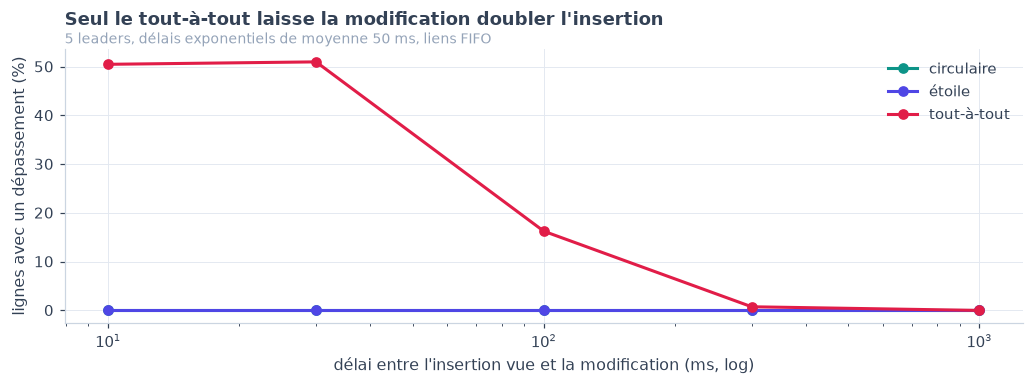

In [3]:
rows = []
for kind, lab in [("circulaire", "circulaire"), ("etoile", "étoile"), ("tout", "tout-à-tout")]:
    topo = rp.topology(kind, [f"L{i}" for i in range(1, 6)])
    hops = max(max(rp.propagate(topo, o).values()) for o in topo)
    rows.append({"topologie": lab, "sauts max": hops})
delais = rng.exponential(50, (200000, 4))
rows[0]["délai jusqu'au dernier (ms)"] = delais.sum(axis=1).mean()
rows[1]["délai jusqu'au dernier (ms)"] = (delais[:, 0] + delais[:, 1:].max(axis=1)).mean()
rows[2]["délai jusqu'au dernier (ms)"] = delais.max(axis=1).mean()
for r_, p in zip(rows, [0.995 ** 5, 0.995, 1.0]):
    r_["tout est relayé (%)"] = 100 * p
display(pd.DataFrame(rows).set_index("topologie").round(1))

def lat_exp(rng_, s, d):
    return rng_.expovariate(1 / 0.05)
gaps = [0.01, 0.03, 0.1, 0.3, 1.0]
res = {k: [] for k in ("circulaire", "etoile", "tout")}
for g in gaps:
    for k in res:
        r_ = rp.run_topology(k, n_nodes=5, n_rows=400, gap=g, latency=lat_exp, seed=2)
        res[k].append(100 * r_["violations"] / 400)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for (k, v), c in zip(res.items(), [TEAL, INDIGO, ROSE]):
    ax.plot(np.array(gaps) * 1000, v, "o-", color=c, label={"circulaire": "circulaire", "etoile": "étoile", "tout": "tout-à-tout"}[k])
ax.set_xscale("log"); ax.set_xlabel("délai entre l'insertion vue et la modification (ms, log)")
ax.set_ylabel("lignes avec un dépassement (%)")
ax.set_title("Seul le tout-à-tout laisse la modification doubler l'insertion")
subtitle(ax, "5 leaders, délais exponentiels de moyenne 50 ms, liens FIFO")
ax.legend()
plt.tight_layout(); plt.show()

Les délais simulés confirment le calcul (200, 142 et 104 ms). Le dépassement est
fréquent en tout-à-tout tant que le délai entre insertion et modification est comparable
au délai réseau, et disparaît quand il le dépasse largement ; il est nul ailleurs. Le
tout-à-tout reste en général le bon choix (tolérance aux pannes, faible latence), à
condition de **suivre la causalité** (vecteurs de versions, ou au minimum mise en attente
des mises à jour orphelines).

> **À retenir.** Toutes les topologies coûtent n - 1 messages par écriture ; elles
> diffèrent par la latence, la fragilité face aux pannes et l'ordre de livraison.

## Exercice 6.9 : choisir n, w et r

**Énoncé.** Une base à la Dynamo stocke chaque clé sur $n = 5$ nœuds, chacun disponible
99 % du temps (pannes indépendantes). Les temps de réponse des nœuds sont log-normaux de
médiane 2 ms avec 2 % de réponses lentes (40 ms).

1. Pour $(w, r) \in \{(3, 3), (5, 1), (1, 5), (4, 2), (2, 2)\}$ : la condition de quorum
   est-elle respectée ? Combien de pannes tolère-t-on en écriture et en lecture ? Quelle
   est la disponibilité de chaque opération ?
2. Pour $w = r = 1$, combien de temps après l'acquittement d'une écriture faut-il attendre
   pour que la probabilité de lecture périmée passe sous 1 % (délais réseau exponentiels
   de moyenne 1 ms) ?
3. Quel est le p99 de la latence de lecture pour $r = 1, 3, 5$ ?
4. Pourquoi un quorum approximatif (sloppy) avec $w = 3$ ne garantit-il pas qu'une lecture
   à $r = 3$ voie l'écriture ?

**Rappels.** Quorums, disponibilité « k sur n », modèle PBS, latence du r-ième plus rapide,
quorum approximatif (cours 4, sections 3 à 5).

**Solution.**

*1.* Condition $w + r > 5$ : oui pour (3, 3), (5, 1), (1, 5), (4, 2) ; non pour (2, 2). On
tolère $5 - w$ pannes en écriture, $5 - r$ en lecture. Disponibilités (formule binomiale,
tableau ci-dessous) : (3, 3) disponible à $1 - 10^{-5}$ dans les deux sens ; (5, 1)
: écriture à $0{,}99^5 \approx 95\,\%$ seulement ; (4, 2) : écriture à 99,9 %.

*2.* On lit la courbe PBS pour $n = 5$, $w = r = 1$ (calcul ci-dessous).

*3.* La latence de lecture est celle de la $r$-ième réponse ; $r = 5$ tombe sur une réponse
lente dès qu'un des cinq nœuds est lent ($1 - 0{,}98^5 \approx 10\,\%$ des lectures), donc
un p99 à 40 ms ; $r = 1$ ne l'est que si les cinq le sont.

*4.* Les 3 acquittements peuvent venir de nœuds de **secours**, extérieurs aux 5 nœuds
attitrés ; une lecture qui interroge 3 des 5 nœuds attitrés n'a alors aucune intersection
garantie avec l'écriture, tant que le transfert différé n'a pas eu lieu.

,w + r > n,"pannes tolérées (écr., lect.)",indispo. écriture,indispo. lecture,lecture périmée (statique)
"(w, r)",,,,,
"(3, 3)",True,"2, 2",9.851e-06,9.851e-06,0.0
"(5, 1)",True,"0, 4",4.901e-02,1.000e-10,0.0
"(1, 5)",True,"4, 0",1.000e-10,4.901e-02,0.0
"(4, 2)",True,"1, 3",9.801e-04,4.960e-08,0.0
"(2, 2)",False,"3, 3",4.960e-08,4.960e-08,0.3


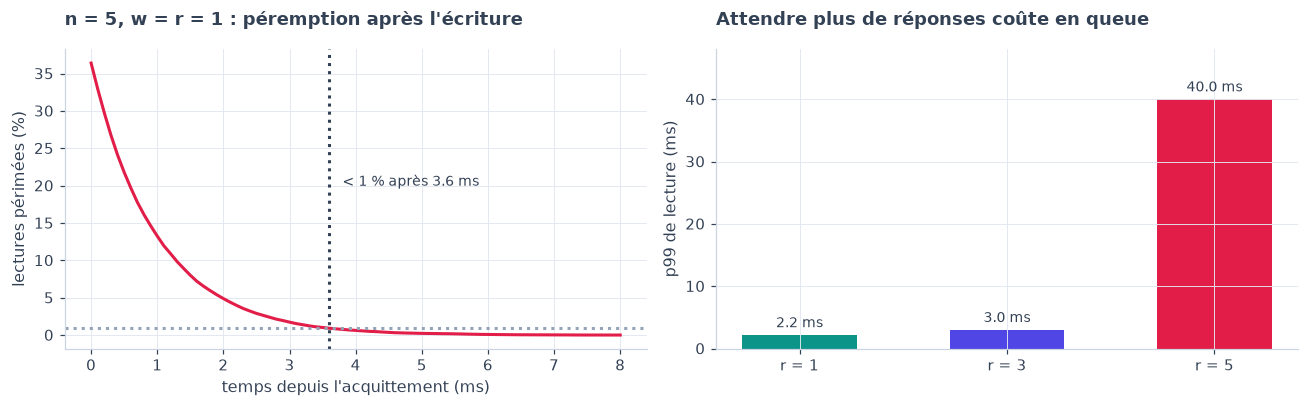

In [4]:
rows = []
for w, r in [(3, 3), (5, 1), (1, 5), (4, 2), (2, 2)]:
    rows.append({"(w, r)": f"({w}, {r})", "w + r > n": w + r > 5, "pannes tolérées (écr., lect.)": f"{5 - w}, {5 - r}",
                 "indispo. écriture": 1 - rp.k_of_n(0.99, w, 5), "indispo. lecture": 1 - rp.k_of_n(0.99, r, 5),
                 "lecture périmée (statique)": rp.p_stale_static(5, w, r)})
display(pd.DataFrame(rows).set_index("(w, r)"))
deltas = np.linspace(0, 8, 81)
ps = rp.pbs_stale_probability(5, 1, 1, deltas, trials=60000, seed=3)
seuil = deltas[np.argmax(ps < 0.01)]
N = 200000
t = rng.lognormal(np.log(2), 0.3, (N, 5)); t = np.where(rng.random((N, 5)) < 0.02, 40.0, t)
p99 = {r: np.percentile(np.sort(t, axis=1)[:, r - 1], 99) for r in (1, 3, 5)}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(deltas, ps * 100, color=ROSE); axes[0].axhline(1, color=GRAY, ls=":")
axes[0].axvline(seuil, color=SLATE, ls=":"); axes[0].text(seuil + 0.2, 20, f"< 1 % après {seuil:.1f} ms", fontsize=9)
axes[0].set_xlabel("temps depuis l'acquittement (ms)"); axes[0].set_ylabel("lectures périmées (%)")
axes[0].set_title("n = 5, w = r = 1 : péremption après l'écriture")
axes[1].bar([f"r = {r}" for r in p99], list(p99.values()), color=[TEAL, INDIGO, ROSE], width=0.55)
annotate_bars(axes[1], "{:.1f} ms"); axes[1].set_ylabel("p99 de lecture (ms)"); axes[1].set_title("Attendre plus de réponses coûte en queue")
axes[1].set_ylim(0, max(p99.values()) * 1.2)
finish(fig); plt.show()

Avec $w = r = 1$, il faut attendre quelques millisecondes après l'acquittement pour que la
péremption tombe sous 1 % ; avec un quorum strict, elle est nulle d'emblée dans ce modèle,
au prix d'une latence de lecture qui dépend de la $r$-ième réponse : $r = 5$ hérite de la
moindre lenteur d'un nœud.

> **À retenir.** (w, r) se choisit en fonction de trois contraintes : recouvrement
> (w + r > n), pannes tolérées de chaque côté (n - w, n - r) et latence de queue (la w-ième
> ou r-ième réponse).

## Exercice 6.10 : vecteurs de versions à la main

**Énoncé.** Deux répliques A et B d'une base sans leader suivent la causalité par
vecteurs de versions pointés. Clé `x`, initialement absente. Séquence :

1. le client 1 écrit « a » sur A sans contexte ;
2. le client 2 écrit « b » sur B sans contexte ;
3. anti-entropie : A reçoit l'état de B ;
4. le client 3 lit sur A, puis écrit « c » sur A avec le contexte lu ;
5. le client 2, qui n'a pas relu, écrit « b2 » sur B avec le contexte de sa première
   écriture ;
6. anti-entropie dans les deux sens.

Donner après chaque étape les frères et le contexte de chaque réplique, puis l'état final.
Que donnerait LWW si les horodatages suivent l'ordre des étapes ? Vérifier avec
`rp.DottedReplica`.

**Rappels.** Vecteurs de versions pointés : une écriture écrase les frères couverts par
le contexte fourni, garde les autres ; l'anti-entropie garde ce qui n'est pas couvert par
le contexte de l'autre (cours 5, section 5, section *Version vectors*).

**Solution.**

1. A : frères {a@(A,1)}, contexte {A:1}.
2. B : frères {b@(B,1)}, contexte {B:1}.
3. A fusionne : aucun des deux points n'est couvert par le contexte de l'autre, A garde
   {a, b}, contexte {A:1, B:1}.
4. Client 3 lit {a, b} avec le contexte {A:1, B:1}, écrit « c » : les deux frères sont
   couverts, A garde {c@(A,2)}, contexte {A:2, B:1}.
5. Client 2 écrit « b2 » sur B avec le contexte {B:1} : écrase b, B garde {b2@(B,2)},
   contexte {B:2}.
6. Fusion : c@(A,2) n'est pas couvert par {B:2} ; b2@(B,2) n'est pas couvert par
   {A:2, B:1} : les deux survivent. État final sur A et B : frères {c, b2}, contexte
   {A:2, B:2}. C'est juste : « c » a été écrit en connaissance de a et b, mais pas de b2,
   et « b2 » ignorait c.

Avec LWW, seule « b2 » (étape 5, la plus tardive) survivrait : l'écriture « c », qui
résumait a et b, serait perdue, et avec elle « a ».

In [5]:
A, B = rp.DottedReplica("A"), rp.DottedReplica("B")
etats = []
def note(etape):
    etats.append({"étape": etape, "A : frères": A.get("x")[0], "A : contexte": A.get("x")[1],
                  "B : frères": B.get("x")[0], "B : contexte": B.get("x")[1]})
A.put("x", "a", None); note("1. a sur A")
_, ctx2 = B.put("x", "b", None); note("2. b sur B")
A.sync_from(B, "x"); note("3. A <- B")
vals, ctx = A.get("x"); A.put("x", "c", ctx); note("4. c sur A (contexte lu)")
B.put("x", "b2", {"B": 1}); note("5. b2 sur B (contexte {B:1})")
A.sync_from(B, "x"); B.sync_from(A, "x"); note("6. anti-entropie")
pd.DataFrame(etats).set_index("étape")

,A : frères,A : contexte,B : frères,B : contexte
étape,,,,
1. a sur A,[a],{'A': 1},[],{}
2. b sur B,[a],{'A': 1},[b],{'B': 1}
3. A <- B,"[a, b]","{'A': 1, 'B': 1}",[b],{'B': 1}
4. c sur A (contexte lu),[c],"{'A': 2, 'B': 1}",[b],{'B': 1}
5. b2 sur B (contexte {B:1}),[c],"{'A': 2, 'B': 1}",[b2],{'B': 2}
6. anti-entropie,"[c, b2]","{'A': 2, 'B': 2}","[c, b2]","{'B': 2, 'A': 2}"


In [6]:
lww = rp.lww_resolve([(1, "A", "a"), (2, "B", "b"), (4, "A", "c"), (5, "B", "b2")])
print("LWW garde :", lww[2], "| vecteurs pointés gardent :", sorted(A.get("x")[0]))

LWW garde : b2 | vecteurs pointés gardent : ['b2', 'c']


La table reproduit le raisonnement étape par étape. Le client qui lira ensuite recevra
{c, b2} et devra les fusionner (par exemple en union, ou en demandant à l'utilisateur) ;
rien n'a été perdu.

> **À retenir.** Un vecteur de versions dit exactement ce qu'une écriture a vu : elle
> écrase ce qui est couvert par son contexte et coexiste avec le reste ; LWW, lui, ne
> garde qu'une valeur.

## Exercice 6.11 : concevoir et tester des CRDT

**Énoncé.**

1. Montrer que la fusion d'un G-Counter (maximum case par case) est commutative,
   associative et idempotente, et expliquer pourquoi ces trois propriétés suffisent à la
   convergence quel que soit l'ordre et le nombre des échanges.
2. Un **2P-Set** (ensemble à deux phases) garde un ensemble d'ajouts et un ensemble de
   suppressions (pierres tombales), tous deux croissants ; la valeur est
   ajouts - suppressions. Implémenter sa fusion. Quelle est sa limite par rapport à
   l'OR-Set ? Illustrer avec le scénario : ajouter « dvd », le retirer, puis le ré-ajouter
   sur une autre réplique.
3. Écrire un test aléatoire qui vérifie la convergence d'un CRDT par état donné.

**Rappels.** CRDT par état, fusion par borne supérieure, OR-Set (cours 6, section 4,
section *Conflict-free replicated datatypes and operational transformation*).

**Solution.**

*1.* Pour chaque case, $\max(a, b) = \max(b, a)$ (commutativité),
$\max(\max(a, b), c) = \max(a, \max(b, c))$ (associativité), $\max(a, a) = a$
(idempotence) ; c'est vrai case par case, donc pour les vecteurs. Conséquence : l'état
d'une réplique après une suite quelconque de fusions est le maximum de tous les états
qu'elle a reçus (directement ou indirectement), indépendamment de l'ordre (commutativité,
associativité) et des doublons (idempotence). Deux répliques qui ont reçu les mêmes mises
à jour ont donc le même état. De plus, chaque réplique n'incrémente que **sa** case : le
maximum n'écrase jamais un incrément d'une autre.

*2.* Fusion : union des ajouts, union des suppressions. Limite : une fois supprimé, un
élément ne peut **jamais** revenir (sa pierre tombale l'emporte sur tout ajout futur),
alors que l'OR-Set, qui étiquette chaque ajout, laisse un nouvel ajout survivre.

In [7]:
from ddia import crdt

class TwoPSet:
    def __init__(self):
        self.ajouts, self.supprs = set(), set()
    def add(self, e): self.ajouts.add(e)
    def remove(self, e):
        if e in self.ajouts: self.supprs.add(e)
    def merge(self, o):
        self.ajouts |= o.ajouts; self.supprs |= o.supprs
    @property
    def value(self): return self.ajouts - self.supprs

rows = []
for nom, cls in [("2P-Set", lambda n: TwoPSet()), ("OR-Set", lambda n: crdt.ORSet(n))]:
    a, b = cls("A"), cls("B")
    a.add("dvd"); b.merge(a); b.remove("dvd"); a.merge(b)
    a.add("dvd")                                   # ré-ajout après la suppression
    b.merge(a); a.merge(b)
    rows.append({"structure": nom, "valeur finale (A)": sorted(a.value), "valeur finale (B)": sorted(b.value)})
display(pd.DataFrame(rows).set_index("structure"))

def teste_convergence(fabrique, operations, n_essais=300, n_rep=4, seed=0):
    rnd = random.Random(seed)
    ok = 0
    for _ in range(n_essais):
        reps = [fabrique(f"R{i}") for i in range(n_rep)]
        for _ in range(50):
            r = rnd.choice(reps)
            if rnd.random() < 0.7:
                rnd.choice(operations)(r, rnd)
            else:
                r.merge(rnd.choice(reps))
        paires = [(i, j) for i in range(n_rep) for j in range(n_rep) if i != j] * 2
        rnd.shuffle(paires)
        for i, j in paires:
            reps[i].merge(reps[j])
        ok += len({repr(sorted(r.value)) if isinstance(r.value, set) else repr(r.value) for r in reps}) == 1
    return ok / n_essais

ops_set = [lambda r, rnd: r.add(rnd.choice("abcd")), lambda r, rnd: r.remove(rnd.choice("abcd"))]
ops_cpt = [lambda r, rnd: r.inc(), lambda r, rnd: r.dec()]
pd.DataFrame({"convergence (%)": [100 * teste_convergence(lambda n: TwoPSet(), ops_set),
                                  100 * teste_convergence(crdt.ORSet, ops_set),
                                  100 * teste_convergence(crdt.PNCounter, ops_cpt)]},
             index=["2P-Set", "OR-Set", "PN-Counter"])

,valeur finale (A),valeur finale (B)
structure,,
2P-Set,[],[]
OR-Set,[dvd],[dvd]


,convergence (%)
2P-Set,100.0
OR-Set,100.0
PN-Counter,100.0


Les trois structures convergent dans tous les essais ; mais le 2P-Set refuse le ré-ajout
du DVD (valeur finale vide), là où l'OR-Set le garde. Converger ne suffit pas : il faut
aussi que la **sémantique** de la fusion corresponde à l'intention des utilisateurs.

> **À retenir.** Une fusion commutative, associative et idempotente garantit la
> convergence ; le choix de la structure (2P-Set, OR-Set...) fixe ce que « fusionner »
> veut dire, en particulier pour les suppressions.

## Exercice 6.12 : texte collaboratif

**Énoncé.** Texte initial « chat ».

1. *OT.* Le site A supprime le caractère en position 0 (« hat ») ; en concurrence, le site
   B insère « s » en position 4 (« chats »). Calculer à la main les opérations
   transformées et le texte final sur chaque site. Même question si B insère « C » en
   position 0 au lieu de « s » en 4.
2. *CRDT.* Avec un RGA, A et B insèrent en concurrence « X » et « Y » au même endroit
   (après le « c »). Quel ordre obtient-on, et pourquoi est-il le même partout ?
3. *Fuzzing.* Une transformation erronée oublie de départager deux insertions à la même
   position (elle décale toujours l'insertion transformée). Montrer par un test
   aléatoire que les sites divergent alors.

**Rappels.** Transformation des positions, identifiants uniques des CRDT de séquence
(cours 6, section 5).

**Solution.**

*1.* A = suppr(0), B = ins(4, « s »). Sur A, on applique B transformé par A : la
suppression est **avant** la position 4, donc ins(3, « s ») : « hat » devient « hats ». Sur
B, on applique A transformé par B : la suppression en 0 est avant l'insertion, inchangée :
« chats » devient « hats ». Deuxième cas, B = ins(0, « C ») : sur A, l'insertion en 0 face
à une suppression en 0 reste ins(0) (« Chat ») ; sur B, la suppression doit viser
l'ancien « c », décalé en position 1 : suppr(1), « Cchat » devient « Chat ».

*2.* Les deux nouveaux éléments ont pour prédécesseur le même identifiant (celui du
« c ») ; RGA les range par identifiant **décroissant** (compteur, puis nom de réplique).
Si les compteurs sont égaux, « Y » (réplique B) passe avant « X » (réplique A) : toutes les
répliques appliquent la même règle sur les mêmes identifiants, donc obtiennent « cYXhat ».

*3.* Deux insertions concurrentes à la même position sont alors **toutes deux** décalées :
le site A obtient « XY » et le site B « YX ». Il faut une règle commune (ici le nom du
site) pour décider laquelle passe en premier.

In [8]:
def ot_final(base, a, b):
    a2, b2 = crdt.ot_transform_seq([a], [b])
    s1 = crdt.ot_apply(crdt.ot_apply(base, a), b2[0])
    s2 = crdt.ot_apply(crdt.ot_apply(base, b), a2[0])
    return {"B transformé (appliqué sur A)": b2[0], "A transformé (appliqué sur B)": a2[0], "site A": s1, "site B": s2}

display(pd.DataFrame([ot_final("chat", ("del", 0), ("ins", 4, "s", "B")),
                      ot_final("chat", ("del", 0), ("ins", 0, "C", "B"))], index=["cas 1", "cas 2"]))

ra, rb = crdt.RGA("A"), crdt.RGA("B")
rb.apply_all(ra.insert_text(0, "chat"))
ox, oy = ra.insert(1, "X"), rb.insert(1, "Y")
ra.apply(oy); rb.apply(ox)
print("RGA :", ra.text(), rb.text(), "| identifiants :", ox[1], oy[1])

def transform_bogue(a, b):
    if a[0] == "ins" and b[0] == "ins" and a[1] == b[1]:
        return ("ins", a[1] + 1, a[2], a[3])          # bogue : décale toujours, sans départager
    return crdt.ot_transform(a, b)

def fuzz(transform, n=2000, seed=0):
    rnd = random.Random(seed)
    ok = 0
    for _ in range(n):
        base = "".join(rnd.choice("abc") for _ in range(rnd.randint(1, 6)))
        a = ("del", rnd.randrange(len(base))) if rnd.random() < 0.5 else ("ins", rnd.randrange(len(base) + 1), "X", "A")
        b = ("del", rnd.randrange(len(base))) if rnd.random() < 0.5 else ("ins", rnd.randrange(len(base) + 1), "Y", "B")
        s1 = crdt.ot_apply(crdt.ot_apply(base, a), transform(b, a))
        s2 = crdt.ot_apply(crdt.ot_apply(base, b), transform(a, b))
        ok += s1 == s2
    return ok / n

pd.DataFrame({"paires convergentes (%)": [100 * fuzz(crdt.ot_transform), 100 * fuzz(transform_bogue)]},
             index=["transformation correcte", "transformation boguée"])

,B transformé (appliqué sur A),A transformé (appliqué sur B),site A,site B
cas 1,"(ins, 3, s, B)","(del, 0)",hats,hats
cas 2,"(ins, 0, C, B)","(del, 1)",Chat,Chat


RGA : cYXhat cYXhat | identifiants : (5, 'A') (5, 'B')


,paires convergentes (%)
transformation correcte,100.00
transformation boguée,93.55


Les deux cas d'OT donnent le même texte sur les deux sites (« hats », puis « Chat »). Les
insertions concurrentes du RGA sont ordonnées par identifiant, de la même façon partout.
Enfin, le test aléatoire débusque le bogue : une petite part des paires d'opérations
diverge, exactement celles où deux insertions visent la même position. Les cas
limites de l'OT sont nombreux et subtils : c'est une raison de tester par fuzzing (et
l'une des raisons de l'intérêt pour les CRDT, plus simples à prouver corrects).

> **À retenir.** OT transforme les positions en fonction des opérations concurrentes et
> doit traiter tous les cas limites ; un CRDT de séquence ordonne les insertions
> concurrentes par identifiant. Dans les deux cas, le fuzzing est le meilleur filet de
> sécurité.